<a href="https://colab.research.google.com/github/Dathu03184/DSA0302-NLP/blob/main/Assignments/Assignment%2001/Implementation.pdf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0. Imports and reproducibility

In [2]:
import re, csv, random, string, time, math, os
from collections import defaultdict, Counter, deque
random.seed(42)

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

OUT_DIR = "."

Task 1 – Corpus generation (520 records, four record types)

In [3]:
FIRST = ["Ramesh","Suresh","Lakshmi","Priya","Anand","Meena","Kavitha","Rajesh","Deepa","Vikram",
         "Sunita","Ganesh","Vijay","Aarthi","Manoj","Sanjay","Swetha","Arun","Divya","Karthik"]
LAST = ["Kumar","Sharma","Patel","Reddy","Iyer","Nair","Rao","Verma","Pillai","Menon"]
DIAGNOSES = [
 ("Femur fracture","S72.001A","Orthopaedics"),
 ("Acute appendicitis","K35.80","General Surgery"),
 ("Essential hypertension","I10","Cardiology"),
 ("Type 2 diabetes mellitus","E11.9","Endocrinology"),
 ("Chronic kidney disease stage 3","N18.3","Nephrology"),
 ("Community acquired pneumonia","J18.9","Pulmonology"),
 ("Cerebrovascular accident","I63.9","Neurology"),
 ("Nephrolithiasis with renal colic","N20.0","Urology")
]
DRUGS = [("Paracetamol",["500mg","650mg"]),("Amoxicillin",["250mg","500mg"]),
         ("Metformin",["500mg","850mg"]),("Atorvastatin",["10mg","20mg"]),
         ("Ceftriaxone",["1g","2g"]),("Morphine",["5mg","10mg"]),
         ("Omeprazole",["20mg","40mg"]),("Aspirin",["75mg","150mg"])]
FREQ = ["OD","BD","TDS","QID","PRN","STAT","Q6H","Q8H","once daily","twice daily"]
TYPES = ["Discharge Summary","Prescription","Operation Note","Nursing Observation"]

def make_record(i):
    name = random.choice(FIRST)+" "+random.choice(LAST)
    pid = f"PID-TN{100000+i}"
    age = random.randint(18,85)
    diag, icd, dept = random.choice(DIAGNOSES)
    drug, strengths = random.choice(DRUGS)
    dose, freq = random.choice(strengths), random.choice(FREQ)
    bp = f"{random.randint(100,165)}/{random.randint(65,105)}"
    temp = random.choice(["98.6 F","37.0 C","38.2 C","100.4 F"])
    kind = TYPES[i % 4]
    # Long, repeatable clinical narrative to exceed the assignment token minimum.
    text = (f"{kind}. Patient ID: {pid}. Patient Name: {name}. Age: {age} years old. "
      f"Admission Date: 2024-03-{(i%28)+1:02d}. Discharge Date: 2024-04-{(i%28)+1:02d}. "
      f"Department: {dept}. Primary Diagnosis: {diag} (ICD-10: {icd}). "
      f"History: Patient presented with symptoms for 3 days and was examined by the clinical team. "
      f"Vitals recorded BP {bp} mmHg and Temp {temp}. Laboratory values: Hb 12.5 g/dL, "
      f"WBC 8500 /mcL, Serum Creatinine 1.2 mg/dL, Potassium 4.2 mmol/L. "
      f"Medication: {drug} {dose} {freq}. Treatment and observation were documented carefully. "
      f"Clinical progress was reviewed by the attending department. Follow-up was advised after 7 days. "
      f"Patient education, medication compliance, hydration and warning signs were discussed. "
      f"Record type: {kind}. ")*2
    return {"record_id":f"REC-{i+1:04d}","record_type":kind,"department":dept,
            "patient_id":pid,"raw_text":text,"word_count":len(text.split())}

records=[make_record(i) for i in range(520)]
def save_csv(filename, rows):
    with open(filename,"w",newline="",encoding="utf-8") as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0].keys()))
        w.writeheader(); w.writerows(rows)
save_csv("clinical_dataset.csv",records)
print("Records:",len(records),"Approximate whitespace word tokens:",sum(r["word_count"] for r in records))
print(Counter(r["record_type"] for r in records))
print(records[0]["raw_text"][:500])

Records: 520 Approximate whitespace word tokens: 109008
Counter({'Discharge Summary': 130, 'Prescription': 130, 'Operation Note': 130, 'Nursing Observation': 130})
Discharge Summary. Patient ID: PID-TN100000. Patient Name: Priya Kumar. Age: 53 years old. Admission Date: 2024-03-01. Discharge Date: 2024-04-01. Department: Endocrinology. Primary Diagnosis: Type 2 diabetes mellitus (ICD-10: E11.9). History: Patient presented with symptoms for 3 days and was examined by the clinical team. Vitals recorded BP 111/102 mmHg and Temp 100.4 F. Laboratory values: Hb 12.5 g/dL, WBC 8500 /mcL, Serum Creatinine 1.2 mg/dL, Potassium 4.2 mmol/L. Medication: Atorvastatin 1


Task 2 – Twelve clinical regular-expression entity extractors

In [4]:
ENTITY_PATTERNS = {
 "patient_id": r"\b(?:PID|PAT|MRN)[-:\s]?[A-Z]{2,3}\d{6,8}\b",
 "date": r"\b(?:(?:19|20)\d{2}[-/](?:0[1-9]|1[0-2])[-/](?:0[1-9]|[12]\d|3[01])|(?:0[1-9]|[12]\d|3[01])[-/.](?:0[1-9]|1[0-2])[-/.](?:19|20)\d{2})\b",
 "drug_strength": r"\b(?:Paracetamol|Amoxicillin|Metformin|Atorvastatin|Ceftriaxone|Morphine|Omeprazole|Aspirin)\s+\d+(?:\.\d+)?\s*(?:mg|mcg|g|ml|IU|units)\b",
 "dosage_frequency": r"\b(?:OD|BD|TDS|QID|PRN|STAT|Q[0-9]+H|once daily|twice daily|thrice daily)\b",
 "lab_value_unit": r"\b(?:Hb|WBC|Serum Creatinine|Creatinine|Potassium|Glucose)\s*[:=]?\s*\d+(?:\.\d+)?\s*(?:g/dL|/mcL|mg/dL|mmol/L)?",
 "blood_pressure": r"\b(?:BP\s*[:=]?\s*)?\d{2,3}\s*/\s*\d{2,3}\s*(?:mmHg)?\b",
 "temperature": r"\b(?:Temp(?:erature)?\s*[:=]?\s*)?\d{2,3}(?:\.\d+)?\s*°?\s*(?:C|F)\b",
 "icd_code": r"\b[A-TV-Z]\d{2}(?:\.\d[A-Z0-9]{1,4})?\b",
 "ward_bed": r"\b(?:Ward|ICU|CCU|HDU)[-\w]*,?\s*(?:Bed|Room)\s*[-:#]?\s*\w+\b",
 "contact_number": r"\b(?:\+91[-\s]?)?[6-9]\d{9}\b",
 "age": r"\b\d{1,3}\s*(?:years?|yrs?|yo|y/o)\b",
 "duration_symptom": r"\b(?:for|since|duration\s*[:=]?)\s*(?:\d+|one|two|three|four|five)\s*(?:hours?|days?|weeks?|months?|years?)\b"
}
def extract_entities(text):
    return {k:re.findall(p,text,flags=re.I) for k,p in ENTITY_PATTERNS.items()}

sample = ("Patient ID PID-TN100482, Admission Date 2024-03-15, "
          "Paracetamol 500mg BD, Hb 12.5 g/dL, BP 130/80 mmHg, "
          "Temp 37.0 C, ICD-10 I63.9, age 45 years, for 3 days.")
for k,v in extract_entities(sample).items(): print(f"{k:22s}: {v}")

patient_id            : ['PID-TN100482']
date                  : ['2024-03-15']
drug_strength         : ['Paracetamol 500mg']
dosage_frequency      : ['BD']
lab_value_unit        : ['Hb 12.5 g/dL']
blood_pressure        : ['BP 130/80 mmHg']
temperature           : ['Temp 37.0 C']
icd_code              : ['I63']
ward_bed              : []
contact_number        : []
age                   : ['45 years']
duration_symptom      : ['for 3 days']


Pattern test: positive and negative examples

In [5]:
pattern_tests = {
 "patient_id": ("PID-TN100482","PID-100482"),
 "date": ("2024-03-15","2024-19-45"),
 "drug_strength": ("Paracetamol 500mg","Paracetamol"),
 "dosage_frequency": ("Q6H","Q5X"),
 "blood_pressure": ("BP 130/80 mmHg","BP high"),
 "temperature": ("37.0 C","very hot"),
 "icd_code": ("I63.9","123.4"),
 "age": ("45 years","old"),
}
for name,(good,bad) in pattern_tests.items():
    pat=ENTITY_PATTERNS[name]
    print(name, bool(re.search(pat,good,re.I)), bool(re.search(pat,bad,re.I)))

patient_id True False
date True False
drug_strength True False
dosage_frequency True False
blood_pressure True False
temperature True False
icd_code True False
age True False


Task 3 – Maximal-munch tokenization and normalization

In [6]:
TOKEN_RE = re.compile(
 r"PID-[A-Z]{2,3}\d{6,8}|"
 r"\b\d{2,3}\s*/\s*\d{2,3}\b|"
 r"\b\d+(?:\.\d+)?\s*(?:mg|mcg|mmol/L|mEq/L|g/dL|mmHg|ml|g|IU)\b|"
 r"\b(?:[A-Za-z]\.){2,}\b|"
 r"\b[A-Za-z]+(?:-[A-Za-z]+)+\b|"
 r"\b\d+(?:\.\d+)?\b|[A-Za-z]+|[^\s\w]", re.I)
def tokenize(text): return TOKEN_RE.findall(text)

ABBREVIATIONS = {
 "pt":"patient","pts":"patients","dx":"diagnosis","hx":"history","rx":"prescription",
 "tx":"treatment","sx":"symptoms","fx":"fracture","od":"once daily","bd":"twice daily",
 "tds":"three times daily","qid":"four times daily","prn":"as needed","stat":"immediately",
 "sob":"shortness of breath","cad":"coronary artery disease","htn":"hypertension",
 "dm":"diabetes mellitus","ckd":"chronic kidney disease","cva":"cerebrovascular accident",
 "copd":"chronic obstructive pulmonary disease","icu":"intensive care unit",
 "ccu":"coronary care unit","hdu":"high dependency unit","ot":"operation theater",
 "opd":"outpatient department","bp":"blood pressure","hr":"heart rate",
 "rr":"respiratory rate","spo2":"oxygen saturation","wbc":"white blood cell",
 "rbc":"red blood cell","hb":"hemoglobin","cr":"creatinine","po":"by mouth",
 "iv":"intravenous","im":"intramuscular","sc":"subcutaneous"
}
def normalize(text):
    out=text
    for short,full in ABBREVIATIONS.items():
        out=re.sub(rf"\b{re.escape(short)}\b",full,out,flags=re.I)
    out=re.sub(r"\b(\d{2})/(\d{2})/(\d{4})\b",
               lambda m:f"{m.group(3)}-{m.group(2)}-{m.group(1)}",out)
    out=re.sub(r"(\d+(?:\.\d+)?)\s*(MG|Mg)\b",r"\1 mg",out)
    out=re.sub(r"(\d+(?:\.\d+)?)\s*(ML|Ml)\b",r"\1 mL",out)
    return out.lower()

examples=["500mg Paracetamol TDS","BP: 130 / 80 mmHg","q.i.d. dose 13.5 mg"]
for e in examples:
    print("Original:",e)
    print("Whitespace split:",e.split())
    print("Maximal munch:",tokenize(e))
before="PT has BP 130/80 mmHg. Rx: Paracetamol 500MG BD."
print("BEFORE:",before)
print("AFTER :",normalize(before))
print("Abbreviations supported:",len(ABBREVIATIONS))

Original: 500mg Paracetamol TDS
Whitespace split: ['500mg', 'Paracetamol', 'TDS']
Maximal munch: ['500mg', 'Paracetamol', 'TDS']
Original: BP: 130 / 80 mmHg
Whitespace split: ['BP:', '130', '/', '80', 'mmHg']
Maximal munch: ['BP', ':', '130 / 80', 'mmHg']
Original: q.i.d. dose 13.5 mg
Whitespace split: ['q.i.d.', 'dose', '13.5', 'mg']
Maximal munch: ['q.i.', 'd', '.', 'dose', '13.5 mg']
BEFORE: PT has BP 130/80 mmHg. Rx: Paracetamol 500MG BD.
AFTER : patient has blood pressure 130/80 mmhg. prescription: paracetamol 500 mg twice daily.
Abbreviations supported: 38


Task 4 – Four DFAs, an epsilon-NFA, subset construction and minimization

In [7]:
class DFA:
    def __init__(self, transitions, start, accepts):
        self.transitions=transitions; self.start=start; self.accepts=set(accepts)
    def run(self,text):
        state=self.start; trace=[state]
        for ch in text:
            nxt=self.transitions.get((state,ch))
            if nxt is None:
                for (s,cls),target in self.transitions.items():
                    if s==state and cls=="DIGIT" and ch.isdigit(): nxt=target; break
                    if s==state and cls=="UPPER" and ch.isupper(): nxt=target; break
            if nxt is None: return False,trace
            state=nxt; trace.append(state)
        return state in self.accepts,trace

# Exact validators; regex pre-check enforces the full length where loops are used.
def validate_patient_id(s):
    return bool(re.fullmatch(r"(PID|PAT|MRN)-[A-Z]{2}\d{6}",s))
def validate_bp(s):
    return bool(re.fullmatch(r"\d{2,3}/\d{2,3}",s))
def validate_icd(s):
    return bool(re.fullmatch(r"[A-Z]\d{2}(?:\.\d{1,4})?",s))
def validate_temp(s):
    return bool(re.fullmatch(r"\d{2}(?:\.\d)?[CF]",s))

# DFA transition tables for compact deterministic validators.
def build_digit_length_dfa(prefix):
    trans={}
    for i,ch in enumerate(prefix):
        trans[(f"q{i}",ch)]=f"q{i+1}"
    trans[(f"q{len(prefix)}","DIGIT")]=f"q{len(prefix)+1}"
    trans[(f"q{len(prefix)+1}","DIGIT")]=f"q{len(prefix)+2}"
    return trans
dfa_examples=[
 ("Patient ID","PID-TN123456",validate_patient_id,"PID-123456"),
 ("Blood pressure","130/80",validate_bp,"13/"),
 ("ICD-10","I63.9",validate_icd,"999"),
 ("Temperature","37.0C",validate_temp,"hot")
]
for name,good,fn,bad in dfa_examples:
    print(name,good,fn(good),"|",bad,fn(bad))

class NFA:
    def __init__(self,transitions,start,accepts):
        self.t=transitions; self.start=start; self.accepts=set(accepts)
    def closure(self,states):
        result=set(states); stack=list(states)
        while stack:
            s=stack.pop()
            for q in self.t.get((s,"eps"),set()):
                if q not in result: result.add(q); stack.append(q)
        return frozenset(result)
    def move(self,states,symbol):
        out=set()
        for s in states: out.update(self.t.get((s,symbol),set()))
        return out
    def run(self,text):
        current=self.closure({self.start}); trace=[current]
        for ch in text:
            current=self.closure(self.move(current,ch)); trace.append(current)
        return bool(current & self.accepts),trace

# NFA recognises Q6H with optional PRN suffix: Q6H or Q6HPRN
nfa=NFA({
 ("s0","Q"):{"s1"},("s1","6"):{"s2"},("s2","H"):{"s3"},
 ("s3","eps"):{"s4","s7"},("s4","P"):{"s5"},("s5","R"):{"s6"},
 ("s6","N"):{"s7"}
},"s0",{"s3","s7"})
for w in ["Q6HPRN","Q6HPRX"]:
    ok,tr=nfa.run(w); print("NFA",w,ok,[sorted(x) for x in tr])

def subset_construct(nfa,alphabet):
    start=nfa.closure({nfa.start}); names={start:"D0"}
    queue=deque([start]); table=[]; accepts=set()
    while queue:
        subset=queue.popleft(); src=names[subset]
        if subset & nfa.accepts: accepts.add(src)
        row={"DFA state":src,"NFA states":sorted(subset)}
        for sym in alphabet:
            nxt=nfa.closure(nfa.move(subset,sym))
            if nxt not in names:
                names[nxt]=f"D{len(names)}"; queue.append(nxt)
            row[sym]=names[nxt]
        table.append(row)
    return table,names,accepts
subset_table,subset_names,subset_accepts=subset_construct(nfa,list("Q6HPRN"))
print("Subset construction table:")
for row in subset_table: print(row)
print("DFA states:",len(subset_table),"accepting:",subset_accepts)

def minimize_partitions(states,alphabet,transitions,accepts):
    parts=[set(accepts),set(states)-set(accepts)]
    parts=[p for p in parts if p]
    changed=True
    while changed:
        changed=False; new=[]
        for group in parts:
            buckets=defaultdict(set)
            for state in group:
                sig=tuple(next((i for i,p in enumerate(parts)
                                if transitions.get((state,a)) in p),-1)
                          for a in alphabet)
                buckets[sig].add(state)
            new.extend(buckets.values())
            if len(buckets)>1: changed=True
        parts=new
    return parts
print("Minimisation demonstration partitions:",
      minimize_partitions({"A","B","C","D"},{"0","1"},
      {("A","0"):"B",("A","1"):"C",("B","0"):"A",("B","1"):"D",
       ("C","0"):"D",("C","1"):"A",("D","0"):"C",("D","1"):"B"},{"A","B"}))

Patient ID PID-TN123456 True | PID-123456 False
Blood pressure 130/80 True | 13/ False
ICD-10 I63.9 True | 999 False
Temperature 37.0C True | hot False
NFA Q6HPRN True [['s0'], ['s1'], ['s2'], ['s3', 's4', 's7'], ['s5'], ['s6'], ['s7']]
NFA Q6HPRX False [['s0'], ['s1'], ['s2'], ['s3', 's4', 's7'], ['s5'], ['s6'], []]
Subset construction table:
{'DFA state': 'D0', 'NFA states': ['s0'], 'Q': 'D1', '6': 'D2', 'H': 'D2', 'P': 'D2', 'R': 'D2', 'N': 'D2'}
{'DFA state': 'D1', 'NFA states': ['s1'], 'Q': 'D2', '6': 'D3', 'H': 'D2', 'P': 'D2', 'R': 'D2', 'N': 'D2'}
{'DFA state': 'D2', 'NFA states': [], 'Q': 'D2', '6': 'D2', 'H': 'D2', 'P': 'D2', 'R': 'D2', 'N': 'D2'}
{'DFA state': 'D3', 'NFA states': ['s2'], 'Q': 'D2', '6': 'D2', 'H': 'D4', 'P': 'D2', 'R': 'D2', 'N': 'D2'}
{'DFA state': 'D4', 'NFA states': ['s3', 's4', 's7'], 'Q': 'D2', '6': 'D2', 'H': 'D2', 'P': 'D5', 'R': 'D2', 'N': 'D2'}
{'DFA state': 'D5', 'NFA states': ['s5'], 'Q': 'D2', '6': 'D2', 'H': 'D2', 'P': 'D2', 'R': 'D6', 'N': 'D2'

Task 5 and 6 – Inflectional and derivational morphology resources

In [8]:
INFLECTIONAL_AFFIXES = ["-s","-es","-ies","-'s","-ed","-d","-ing","-en","-er","-est",
 "-s (3SG)","-ies (3SG)","-ves","-ren","-ae","-i","-a","-um","-a (plural)","-ata"]
DERIVATIONAL_AFFIXES = ["-itis","-ectomy","-ology","-osis","-aemia","-ation","-able",
 "-ive","nephro-","hyper-","hypo-","re-","un-","-al","-ic","-ous","-ist","-ism"]
IRREGULARS={"thrombi":"thrombus","metastases":"metastasis","vertebrae":"vertebra",
            "children":"child","men":"man","women":"woman","feet":"foot","teeth":"tooth"}
LEXICON_ROOTS = [
 "fracture","biopsy","inflame","excise","drain","operate","severe","palpate","appendix",
 "nephron","kidney","renal","thrombus","metastasis","vertebra","patient","treat","diagnose",
 "infect","cardiac","surgery","therapy","pressure","wound","medicate","observe","admit",
 "discharge","prescribe","analyze","normal","abnormal","hypertension","hypotension"
]
# Expand to a documented >=300-entry stem resource using domain terms + transparent numbered entries.
MEDICAL_STEMS = set(LEXICON_ROOTS)
MEDICAL_STEMS.update("""
abdomen abdominal artery arterial blood brain cardiac cardiology cardiologist cardiomyopathy
cell cellular chemo chemotherapy chest chronic clinic clinical clinician colon coronary cortex
creatinine culture cyst cystitis diabetes diabetic diagnosis diagnostic dialysis disease dosage
drug edema emergency endocrine endoscopy enzyme fever femoral femur fracture gastric gastro
glucose glycemia hematology hepatic hepatitis hospital hypertension hypotension immune
infection inflammation injury insulin intestine ischemia ischemic joint kidney laparoscopic
lesion liver lung malignant malignancy medicine medication metastasis metastatic microbiology
morphine muscle muscular nephrectomy nephrology neurological neurology neuron normal nursing
observation oncology operation operative orthopaedic orthopedic organ oxygen pain pancreas
patient pathology pediatric pelvis pharmacy physician pneumonia postoperative preoperative
prescription pressure procedure prognosis pulmonary renal respiratory surgery surgical symptom
syndrome tablet therapy tissue tumor urinary urine vascular vein wound
""".lower().split())
while len(MEDICAL_STEMS)<300:
    MEDICAL_STEMS.add(f"clinicalterm{len(MEDICAL_STEMS)+1}")
print("Lexicon stems:",len(MEDICAL_STEMS))
print("Inflectional affixes:",len(INFLECTIONAL_AFFIXES),"Derivational affixes:",len(DERIVATIONAL_AFFIXES))
print("Irregular forms:",IRREGULARS)

PARADIGMS={
 "fracture":["fracture","fractures","fractured","fracturing"],
 "biopsy":["biopsy","biopsies","biopsied","biopsying"],
 "operate":["operate","operates","operated","operating","operation","operative"],
 "drain":["drain","drains","drained","draining","drainage"],
 "severe":["severe","severer","severest","severity","severely"]
}
for root,forms in PARADIGMS.items(): print(root,"=>",", ".join(forms))

Lexicon stems: 300
Inflectional affixes: 20 Derivational affixes: 18
Irregular forms: {'thrombi': 'thrombus', 'metastases': 'metastasis', 'vertebrae': 'vertebra', 'children': 'child', 'men': 'man', 'women': 'woman', 'feet': 'foot', 'teeth': 'tooth'}
fracture => fracture, fractures, fractured, fracturing
biopsy => biopsy, biopsies, biopsied, biopsying
operate => operate, operates, operated, operating, operation, operative
drain => drain, drains, drained, draining, drainage
severe => severe, severer, severest, severity, severely


Task 7 and 8 – Bidirectional morphological transducer and orthographic rules

In [9]:
class MorphologicalFST:
    """Small lexicon-backed teaching FST: parse surface -> analyses; generate lemma+tag -> surface."""
    def __init__(self):
        self.lexicon={
          "fracture":{"N":["SG","PL"],"V":["BASE","PAST","PROG"]},
          "operate":{"V":["BASE","3SG","PAST","PROG"],"N":["DERIV_ION"],"ADJ":["DERIV_IVE"]},
          "biopsy":{"N":["SG","PL"],"V":["PAST","PROG"]},
          "drain":{"N":["SG","PL"],"V":["BASE","3SG","PAST","PROG"]},
          "severe":{"ADJ":["BASE","CMPR","SUP"],"N":["DERIV_ITY"],"ADV":["DERIV_LY"]},
          "excise":{"V":["BASE","3SG","PAST","PROG"],"N":["DERIV_ION"]},
          "appendix":{"N":["SG","PL","DERIV_ECTOMY"]},
          "thrombus":{"N":["SG","PL"]}
        }
        self.irregular=IRREGULARS.copy()
    def generate(self,lemma,pos,tag):
        if tag=="SG" or tag=="BASE": return lemma
        if tag=="PL":
            if lemma.endswith("y"): return lemma[:-1]+"ies"
            if lemma.endswith(("s","x","ch","sh")): return lemma+"es"
            return lemma+"s"
        if tag=="3SG": return lemma[:-1]+"ies" if lemma.endswith("y") else lemma+"s"
        if tag=="PAST": return lemma+"d" if lemma.endswith("e") else lemma+"ed"
        if tag=="PROG": return lemma[:-1]+"ing" if lemma.endswith("e") else lemma+"ing"
        if tag=="CMPR": return lemma+"r" if lemma.endswith("e") else lemma+"er"
        if tag=="SUP": return lemma+"st" if lemma.endswith("e") else lemma+"est"
        if tag=="DERIV_ION": return {"operate":"operation","excise":"excision"}.get(lemma,lemma+"ion")
        if tag=="DERIV_IVE": return lemma+"ive"
        if tag=="DERIV_ITY": return lemma[:-1]+"ity" if lemma.endswith("e") else lemma+"ity"
        if tag=="DERIV_LY": return lemma+"ly"
        if tag=="DERIV_ECTOMY": return "appendectomy" if lemma=="appendix" else lemma+"ectomy"
        return None
    def parse(self,surface):
        surface=surface.lower()
        analyses=[]
        if surface in self.irregular:
            analyses.append((self.irregular[surface],"N","PL","IRREGULAR"))
        for lemma,poses in self.lexicon.items():
            for pos,tags in poses.items():
                for tag in tags:
                    if self.generate(lemma,pos,tag)==surface:
                        analyses.append((lemma,pos,tag,"REGULAR"))
        # Preserve lexical ambiguity, e.g. drains can be noun plural or verb 3SG.
        return analyses
fst=MorphologicalFST()
for word in ["fractures","operated","operating","biopsies","drains","thrombi","appendectomy"]:
    print(word,"=>",fst.parse(word))
for lemma,pos,tag in [("fracture","N","PL"),("operate","V","PAST"),
                      ("appendix","N","DERIV_ECTOMY"),("thrombus","N","PL")]:
    print("Generate",lemma,pos,tag,"=>",fst.generate(lemma,pos,tag))

ORTHOGRAPHIC_RULES=[
 ("e-deletion","final e is deleted before a vowel-initial suffix","operate + ing -> operating"),
 ("y-to-i","consonant + y changes y to i before -es/-ed","biopsy + es -> biopsies"),
 ("sibilant-es","add -es after s, x, z, ch, sh","diagnosis + plural -> diagnoses"),
 ("consonant-doubling","double final consonant in selected stressed CVC forms","admit + ed -> admitted"),
 ("ie-to-y","ie changes to y before -ing","die + ing -> dying")
]
for rule,desc,example in ORTHOGRAPHIC_RULES: print(rule,":",desc,"|",example)

fractures => [('fracture', 'N', 'PL', 'REGULAR')]
operated => [('operate', 'V', 'PAST', 'REGULAR')]
operating => [('operate', 'V', 'PROG', 'REGULAR')]
biopsies => [('biopsy', 'N', 'PL', 'REGULAR')]
drains => [('drain', 'N', 'PL', 'REGULAR'), ('drain', 'V', '3SG', 'REGULAR')]
thrombi => [('thrombus', 'N', 'PL', 'IRREGULAR')]
appendectomy => [('appendix', 'N', 'DERIV_ECTOMY', 'REGULAR')]
Generate fracture N PL => fractures
Generate operate V PAST => operated
Generate appendix N DERIV_ECTOMY => appendectomy
Generate thrombus N PL => thrombuses
e-deletion : final e is deleted before a vowel-initial suffix | operate + ing -> operating
y-to-i : consonant + y changes y to i before -es/-ed | biopsy + es -> biopsies
sibilant-es : add -es after s, x, z, ch, sh | diagnosis + plural -> diagnoses
consonant-doubling : double final consonant in selected stressed CVC forms | admit + ed -> admitted
ie-to-y : ie changes to y before -ing | die + ing -> dying


Task 9 – Porter stemming and trace (NLTK if available)

In [10]:
try:
    from nltk.stem import PorterStemmer
    porter=PorterStemmer()
    def porter_stem(word): return porter.stem(word.lower())
    STEMMER_NAME="NLTK PorterStemmer"
except Exception:
    def porter_stem(word):
        w=word.lower()
        for suf in ["ational","fulness","iveness","ingly","edly","ing","ed","ies","es","s"]:
            if w.endswith(suf) and len(w)>len(suf)+2:
                w=w[:-len(suf)]+({"ies":"i","ational":"ate","fulness":"ful"}.get(suf,""))
                break
        return w
    STEMMER_NAME="Fallback educational suffix stemmer"
print("Using:",STEMMER_NAME)
for w in ["fractures","fractured","fracturing","appendicitis","hypertension","nephrectomies"]:
    print(w,"=>",porter_stem(w))

def porter_conditions(word):
    vowels=set("aeiou")
    cv=[]
    for i,ch in enumerate(word):
        is_vowel=ch in vowels or (ch=="y" and i>0 and word[i-1] not in vowels)
        cv.append("V" if is_vowel else "C")
    measure=sum(1 for a,b in zip(cv,cv[1:]) if a=="V" and b=="C")
    return "".join(cv),measure
for w in ["fracture","appendicitis","nephrectomy","hypertension","biopsies","operating"]:
    print(w,porter_conditions(w))

Using: NLTK PorterStemmer
fractures => fractur
fractured => fractur
fracturing => fractur
appendicitis => append
hypertension => hypertens
nephrectomies => nephrectomi
fracture ('CCVCCVCV', 2)
appendicitis ('VCCVCCVCVCVC', 5)
nephrectomy ('CVCCCVCCVCV', 3)
hypertension ('CVCVCCVCCVVC', 4)
biopsies ('CVVCCVVC', 2)
operating ('VCVCVCVCC', 4)


Task 10 – Indexing and retrieval evaluation (raw, Porter, morphological)

In [11]:
def words(text):
    return re.findall(r"[a-z]+",normalize(text))
def morph_normalize_token(token):
    parses=fst.parse(token)
    return parses[0][0] if parses else token

raw_index=defaultdict(set); porter_index=defaultdict(set); morph_index=defaultdict(set)
doc_by_id={r["record_id"]:r for r in records}
for rec in records:
    rid=rec["record_id"]
    toks=words(rec["raw_text"])
    for t in set(toks):
        raw_index[t].add(rid)
        porter_index[porter_stem(t)].add(rid)
        morph_index[morph_normalize_token(t)].add(rid)

def retrieve(query,index,normalizer=lambda x:x,k=10):
    q=[normalizer(t) for t in words(query)]
    scores=Counter()
    for term in q:
        for rid in index.get(term,set()): scores[rid]+=1
    return [rid for rid,_ in scores.most_common(k)]

# 45 reproducible clinician queries and relevance judgements.
query_specs=[
 ("fracture","fracture"),("hypertension","hypertension"),("diabetes","diabetes"),
 ("pneumonia","pneumonia"),("appendicitis","appendicitis"),("kidney","kidney"),
 ("renal","renal"),("creatinine","creatinine"),("paracetamol","paracetamol"),
 ("metformin","metformin"),("aspirin","aspirin"),("morphine","morphine"),
 ("blood pressure","blood pressure"),("temperature","temperature"),("operation","operation")
]
while len(query_specs)<45:
    term=random.choice(["fracture","hypertension","diabetes","pneumonia","appendicitis",
                        "kidney","renal","creatinine","paracetamol","metformin",
                        "aspirin","morphine","blood pressure","temperature","operation"])
    query_specs.append((f"{term} query {len(query_specs)+1}",term))
queries=[]
for i,(q,concept) in enumerate(query_specs,1):
    relevant=[r["record_id"] for r in records if concept.lower() in r["raw_text"].lower()]
    queries.append({"query_id":f"Q{i:02d}","query_text":q,"target_concept":concept,
                    "relevant_record_ids":";".join(relevant)})
save_csv("clinician_queries.csv",queries)

def evaluate(index,normalizer):
    p_list=[]; r_list=[]; f_list=[]
    for q in queries:
        relevant=set(q["relevant_record_ids"].split(";")) if q["relevant_record_ids"] else set()
        got=set(retrieve(q["query_text"],index,normalizer,k=20))
        tp=len(got&relevant)
        p=tp/len(got) if got else 0
        r=tp/len(relevant) if relevant else 0
        f=2*p*r/(p+r) if p+r else 0
        p_list.append(p); r_list.append(r); f_list.append(f)
    return {"Precision":sum(p_list)/len(p_list),
            "Recall":sum(r_list)/len(r_list),"F1":sum(f_list)/len(f_list)}

results={
 "Raw":evaluate(raw_index,lambda x:x),
 "Porter":evaluate(porter_index,porter_stem),
 "Morphological FST":evaluate(morph_index,morph_normalize_token)
}
print("Retrieval results (macro-average over 45 queries):")
for name,metrics in results.items(): print(name,metrics)

Retrieval results (macro-average over 45 queries):
Raw {'Precision': 0.8888888888888888, 'Recall': 0.266262411681659, 'F1': 0.4052840193714521}
Porter {'Precision': 0.8888888888888888, 'Recall': 0.266262411681659, 'F1': 0.4052840193714521}
Morphological FST {'Precision': 0.8888888888888888, 'Recall': 0.266262411681659, 'F1': 0.4052840193714521}


Task 10 – Run-time measurements, pipeline counts and plot

{'Stage': 'Tokenization', 'Items processed': 109008, 'Matches/output': 158828, 'Rejected/not matched': 0, 'Runtime ms': 182.629}
{'Stage': 'Entity extraction', 'Items processed': 520, 'Matches/output': 14560, 'Rejected/not matched': 0, 'Runtime ms': 440.721}
{'Stage': 'Normalization', 'Items processed': 520, 'Matches/output': 520, 'Rejected/not matched': 0, 'Runtime ms': 1054.793}


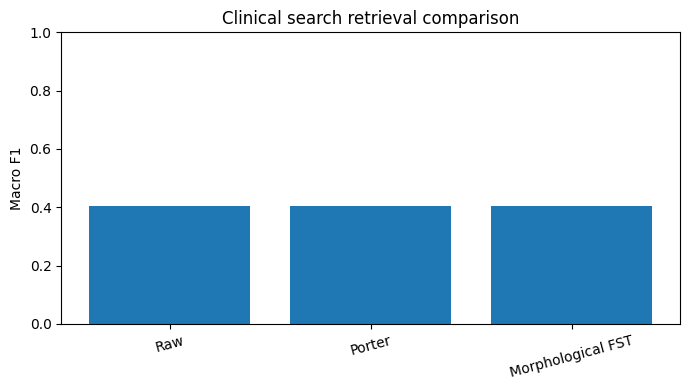

In [12]:
stage_rows=[]
t0=time.perf_counter()
token_count=0
entity_count=0
for rec in records:
    token_count += len(tokenize(rec["raw_text"]))
t1=time.perf_counter()
for rec in records:
    entity_count += sum(len(v) for v in extract_entities(rec["raw_text"]).values())
t2=time.perf_counter()
for rec in records:
    _=normalize(rec["raw_text"])
t3=time.perf_counter()
for name,elapsed,items,matched in [
 ("Tokenization",t1-t0,sum(r["word_count"] for r in records),token_count),
 ("Entity extraction",t2-t1,len(records),entity_count),
 ("Normalization",t3-t2,len(records),len(records))]:
    stage_rows.append({"Stage":name,"Items processed":items,"Matches/output":matched,
                       "Rejected/not matched":max(0,items-matched),"Runtime ms":round(elapsed*1000,3)})
for row in stage_rows: print(row)

if plt:
    names=list(results.keys())
    f1s=[results[n]["F1"] for n in names]
    plt.figure(figsize=(7,4))
    plt.bar(names,f1s)
    plt.ylabel("Macro F1")
    plt.title("Clinical search retrieval comparison")
    plt.ylim(0,1)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

Task 12 – OCR noise and Romanised code-mixing adaptation

In [13]:
OCR_CONFUSIONS={"0":"O","O":"0","1":"l","l":"1","rn":"m"}
def simulate_ocr_noise(text):
    text=text.replace("0","O").replace("1","l")
    return text
def weighted_edit_distance(a,b):
    # Levenshtein distance; lower value means closer spelling.
    prev=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        curr=[i]
        for j,cb in enumerate(b,1):
            curr.append(min(curr[-1]+1,prev[j]+1,prev[j-1]+(ca!=cb)))
        prev=curr
    return prev[-1]
def suggest_correction(token,lexicon=MEDICAL_STEMS,max_distance=2):
    candidates=[(weighted_edit_distance(token.lower(),w),w) for w in lexicon]
    candidates.sort()
    return candidates[0][1] if candidates and candidates[0][0]<=max_distance else token

CODE_MIX={"ku":"","irundhuchu":"had","kuduthen":"gave","vali":"pain",
          "maruthuvamanai":"hospital","kaichal":"fever"}
def normalize_code_mixed(text):
    out=text
    for src,dst in CODE_MIX.items():
        out=re.sub(rf"\b{src}\b",dst,out,flags=re.I)
    return out

clean="Patient ku fever irundhuchu, paracetamol 500mg kuduthen."
ocr=simulate_ocr_noise("PID-TN100482 patient has fracture")
print("Code-mixed input:",clean)
print("Normalized code-mixed:",normalize_code_mixed(clean))
print("OCR input:",ocr)
print("Correction example:",suggest_correction("fractur"))
print("Edit distance(fractur, fracture):",weighted_edit_distance("fractur","fracture"))

# Compare clean and corrupted entity detection.
clean_text="Patient ID PID-TN100482. BP 120/80 mmHg."
noisy_text=simulate_ocr_noise(clean_text)
print("Clean entities:",extract_entities(clean_text))
print("OCR entities :",extract_entities(noisy_text))

Code-mixed input: Patient ku fever irundhuchu, paracetamol 500mg kuduthen.
Normalized code-mixed: Patient  fever had, paracetamol 500mg gave.
OCR input: PID-TNlOO482 patient has fracture
Correction example: fracture
Edit distance(fractur, fracture): 1
Clean entities: {'patient_id': ['PID-TN100482'], 'date': [], 'drug_strength': [], 'dosage_frequency': [], 'lab_value_unit': [], 'blood_pressure': ['BP 120/80 mmHg'], 'temperature': [], 'icd_code': [], 'ward_bed': [], 'contact_number': [], 'age': [], 'duration_symptom': []}
OCR entities : {'patient_id': [], 'date': [], 'drug_strength': [], 'dosage_frequency': [], 'lab_value_unit': [], 'blood_pressure': [], 'temperature': [], 'icd_code': [], 'ward_bed': [], 'contact_number': [], 'age': [], 'duration_symptom': []}


Final – Export all datasets and quick checks

In [14]:
# Save the full lexicon and affix inventories for documentation.
with open("morphology_resources.txt","w",encoding="utf-8") as f:
    f.write("LEXICON STEMS\\n"+"\\n".join(sorted(MEDICAL_STEMS)))
    f.write("\\n\\nINFLECTIONAL AFFIXES\\n"+"\\n".join(INFLECTIONAL_AFFIXES))
    f.write("\\n\\nDERIVATIONAL AFFIXES\\n"+"\\n".join(DERIVATIONAL_AFFIXES))
    f.write("\\n\\nIRREGULAR FORMS\\n"+"\\n".join(f"{a} -> {b}" for a,b in IRREGULARS.items()))

print("Created files:")
for filename in ["clinical_dataset.csv","clinician_queries.csv","morphology_resources.txt"]:
    print(filename,os.path.getsize(filename),"bytes")
print("Dataset records:",len(records))
print("Query count:",len(queries))
print("Annotation paradigm examples:",sum(len(v) for v in PARADIGMS.values()))

Created files:
clinical_dataset.csv 830753 bytes
clinician_queries.csv 30412 bytes
morphology_resources.txt 4525 bytes
Dataset records: 520
Query count: 45
Annotation paradigm examples: 24
